In [1]:
import numpy as np
import json

In [2]:
"You are an airspace tactical deconfliction assistant. At each time step, an ownship agent is approaching a bottleneck waypoint, \n    such as merging or intersections points, where other agents (intruders) are approaching as well. Based on the information of the intruders, \n    the ownship should take an action to avoid collisions. The ownship agent only has access to the information of the front intruders, \n    but there might be other intruders behind the ownship. Your task is to help the ownship aircraft avoid collisions with front intruder aircraft by \n    suggesting appropriate speed adjustments. The ownship cannot unnecessarily decelerate since it might occlude the airspace for other agents behind it.\n    Now, given the ownship state: [v, v_min, v_max delta_d1, delta_d2, delta_dwpt1, delta_dwpt2, delta_v1, delta_v2, same_route1, same_route2],\n    v: ownship speed(m/s), \n    v_min: ownship minimum speed(m/s), \n    v_max: ownship maximum speed(m/s),\n    d1: the absolute distance between the first front intruder (if any) and ownship(m), \n    d2: the absolute distance between the second front intruder (if any) and ownship(m), \n    delta_dwpt1: the absolute difference between the distance to the next waypoint between the first front intruder (if any) and ownship(m), \ndelta_dwpt2: the absolute difference between the distance to the next waypoint between the second front intruder (if any) and ownship(m), \ndelta_v1: signed speed difference between the first front intruder and ownship(m/s), \ndelta_v2: signed speed difference between the second front intruder and ownship(m/s), \nsame_route1: whether the first front intruder is on the same route as the ownship (1: yes, 0: no), \n    same_route2: whether the second front intruder is on the same route as the ownship (1: yes, 0: no). \n    If one of the values is None, it means there is no such front intruder.\nBased on the above information, decide the ownship action: Decelerate / Hold / Accelerate.\n"

'You are an airspace tactical deconfliction assistant. At each time step, an ownship agent is approaching a bottleneck waypoint, \n    such as merging or intersections points, where other agents (intruders) are approaching as well. Based on the information of the intruders, \n    the ownship should take an action to avoid collisions. The ownship agent only has access to the information of the front intruders, \n    but there might be other intruders behind the ownship. Your task is to help the ownship aircraft avoid collisions with front intruder aircraft by \n    suggesting appropriate speed adjustments. The ownship cannot unnecessarily decelerate since it might occlude the airspace for other agents behind it.\n    Now, given the ownship state: [v, v_min, v_max delta_d1, delta_d2, delta_dwpt1, delta_dwpt2, delta_v1, delta_v2, same_route1, same_route2],\n    v: ownship speed(m/s), \n    v_min: ownship minimum speed(m/s), \n    v_max: ownship maximum speed(m/s),\n    d1: the absolute di

In [3]:
def initial_prompt(ownship_intruder_info):
    
    def safe_float(val):
        return float('nan') if val is None else float(val)

    ownship_info = ownship_intruder_info['ownship_info']
    raw_first = ownship_intruder_info.get('first_closest_front_intruder_info', []) or {}
    if isinstance(raw_first, list) and len(raw_first) > 0:
        first_intruder_info = raw_first[0]
    elif isinstance(raw_first, dict):
        first_intruder_info = raw_first
    else:
        first_intruder_info = {}
    
    # first_intruder_info = (
    #     ownship_intruder_info['first_closest_front_intruder_info'][0]
    #     if ownship_intruder_info['first_closest_front_intruder_info']
    #     else {}
    # )
    raw_second = ownship_intruder_info.get('second_closest_front_intruder_info', []) or {}
    if isinstance(raw_second, list) and len(raw_second) > 0:
        second_intruder_info = raw_second[0]
    elif isinstance(raw_second, dict):
        second_intruder_info = raw_second
    else:
        second_intruder_info = {}

    # second_intruder_info = (
    #     ownship_intruder_info['second_closest_front_intruder_info'][0]
    #     if ownship_intruder_info['second_closest_front_intruder_info']
    #     else {}
    # )
    ownship_action = ownship_intruder_info['ownship_action']

    # ---- System prompt (fixed global instruction) ----
    # system_prompt = """You are an airspace tactical deconfliction assistant. At each time step, an ownship agent is approaching a bottleneck waypoint, 
    # such as merging or intersection points, where other agents (intruders) may also be approaching. Based on the information of the intruders, 
    # the ownship should take an action to avoid collisions. The ownship agent only has access to information about the front intruders, 
    # but there might be other intruders behind the ownship. Your task is to help the ownship aircraft avoid collisions with front intruder aircraft by 
    # suggesting appropriate speed adjustments. The ownship cannot unnecessarily decelerate since it might occlude the airspace for other agents behind it.
    # Now, given the ownship state: [v, v_min, v_max, delta_d1, delta_d2, delta_dwpt1, delta_dwpt2, delta_v1, delta_v2, same_route1, same_route2],
    # where:
    #   v: ownship speed (m/s),
    #   v_min: ownship minimum speed (m/s),
    #   v_max: ownship maximum speed (m/s),
    #   d1: distance between the first front intruder (if any) and the ownship (m),
    #   d2: distance between the second front intruder (if any) and the ownship (m),
    #   delta_dwpt1: difference between distances to next waypoint between the first front intruder and the ownship (m),
    #   delta_dwpt2: difference between distances to next waypoint between the second front intruder and the ownship (m),
    #   delta_v1: signed speed difference between the first front intruder and ownship (m/s),
    #   delta_v2: signed speed difference between the second front intruder and ownship (m/s),
    #   same_route1: 1 if the first intruder is on the same route, 0 otherwise,
    #   same_route2: 1 if the second intruder is on the same route, 0 otherwise.
    # If one of the values is None, it means there is no such front intruder.
    # Decide the ownship action: Decelerate / Hold / Accelerate.
    # """
    system_prompt = "You are an airspace tactical deconfliction assistant. At each time step, an ownship agent is approaching a bottleneck waypoint, \n    such as merging or intersections points, where other agents (intruders) are approaching as well. Based on the information of the intruders, \n    the ownship should take an action to avoid collisions. The ownship agent only has access to the information of the front intruders, \n    but there might be other intruders behind the ownship. Your task is to help the ownship aircraft avoid collisions with front intruder aircraft by \n    suggesting appropriate speed adjustments. The ownship cannot unnecessarily decelerate since it might occlude the airspace for other agents behind it.\n    Now, given the ownship state: [v, v_min, v_max delta_d1, delta_d2, delta_dwpt1, delta_dwpt2, delta_v1, delta_v2, same_route1, same_route2],\n    v: ownship speed(m/s), \n    v_min: ownship minimum speed(m/s), \n    v_max: ownship maximum speed(m/s),\n    d1: the absolute distance between the first front intruder (if any) and ownship(m), \n    d2: the absolute distance between the second front intruder (if any) and ownship(m), \n    delta_dwpt1: the absolute difference between the distance to the next waypoint between the first front intruder (if any) and ownship(m), \ndelta_dwpt2: the absolute difference between the distance to the next waypoint between the second front intruder (if any) and ownship(m), \ndelta_v1: signed speed difference between the first front intruder and ownship(m/s), \ndelta_v2: signed speed difference between the second front intruder and ownship(m/s), \nsame_route1: whether the first front intruder is on the same route as the ownship (1: yes, 0: no), \n    same_route2: whether the second front intruder is on the same route as the ownship (1: yes, 0: no). \n    If one of the values is None, it means there is no such front intruder.\nBased on the above information, decide the ownship action: Decelerate / Hold / Accelerate.\n"

    # ---- Build numeric state representation ----
    ownship_spd = ownship_info.get('speed(m/s)', 0.0)
    ownship_min_spd = ownship_info.get('ac_min_spd(m/s)', 0.0)
    ownship_max_spd = ownship_info.get('ac_max_spd(m/s)', 0.0)

    d1 = ownship_info.get('distance_to_intruder1(m)') if ownship_info['num_intruders_ahead'] >= 1 else None
    d2 = ownship_info.get('distance_to_intruder2(m)') if ownship_info['num_intruders_ahead'] >= 2 else None

    delta_dwpt1 = abs(first_intruder_info.get('ac_dist_to_nxt_wpt(m)', 0) - ownship_info['ac_dist_to_nxt_wpt(m)']) if ownship_info['num_intruders_ahead'] >= 1 else None
    delta_dwpt2 = abs(second_intruder_info.get('ac_dist_to_nxt_wpt(m)', 0) - ownship_info['ac_dist_to_nxt_wpt(m)']) if ownship_info['num_intruders_ahead'] >= 2 else None

    delta_v1 = first_intruder_info.get('speed(m/s)', 0) - ownship_spd if ownship_info['num_intruders_ahead'] >= 1 else None
    delta_v2 = second_intruder_info.get('speed(m/s)', 0) - ownship_spd if ownship_info['num_intruders_ahead'] >= 2 else None

    same_route1 = ownship_info.get('intruder1_on_same_route') if ownship_info['num_intruders_ahead'] >= 1 else None
    same_route2 = ownship_info.get('intruder2_on_same_route') if ownship_info['num_intruders_ahead'] >= 2 else None

    # ---- User prompt ----
    user_prompt = (
        "Here is the ownship state information:\n"
        f"[v, v_min, v_max, d1, d2, delta_dwpt1, delta_dwpt2, delta_v1, delta_v2, same_route1, same_route2] = "
        f"[{safe_float(ownship_spd):.2f}, {safe_float(ownship_min_spd):.2f}, {safe_float(ownship_max_spd):.2f}, "
        f"{safe_float(d1):.2f}, {safe_float(d2):.2f}, {safe_float(delta_dwpt1):.2f}, {safe_float(delta_dwpt2):.2f}, "
        f"{safe_float(delta_v1):.2f}, {safe_float(delta_v2):.2f}, {safe_float(same_route1):.0f}, {safe_float(same_route2):.0f}]. "
        "Based on the above information, what actions should the ownship take? Skip the explanation."
    )

    # ---- Assistant target ----
    # "The recommended action for the ownship is to 'Accelerate'. \n"
    assistant_response = f"The recommended action for the ownship is to '{ownship_action.capitalize()}'. \n"

    return system_prompt, user_prompt, assistant_response

In [4]:
# vehicle_speed_categories = {
#     "Amazon Prime Air - MK30 Model": ,
#     "Google X-Wing": ,
# }

def speed_indicator(speed, max_speed):
    """
    Converts a speed value into a categorical indicator: low, medium, or high.
    """
    if speed < 0.15 * max_speed:
        return 'very low'
    elif 0.15 * max_speed <= speed < 0.33 * max_speed:
        return 'low'
    elif 0.33 * max_speed <= speed < 0.55 * max_speed:
        return 'medium'
    elif 0.55 * max_speed <= speed < 0.75 * max_speed:
        return 'high'
    else:
        return 'very high'
    
def desired_speed_indicator(current_speed, max_speed):
    desired_speed = 0.75 * max_speed  # Example desired speed at 75% of max speed

    if current_speed < desired_speed:
        return 'lower'
    else:  
        return 'higher'

def distance_indicator(distance):
    """
    Converts a distance value into a categorical indicator: near, medium, or far.
    """
    safe_distance = 500  # Example maximum distance for categorization
    if distance < 0.5 * safe_distance:
        return 'too unsafe'
    elif 0.5 * safe_distance <= distance <  safe_distance:
        return 'unsafe'
    elif safe_distance <= distance < 1.5 * safe_distance:
        return 'medium safe'
    elif 1.5 * safe_distance <= distance < 2.5 * safe_distance:
        return 'safe'
    else:
        return 'very safe'
    
def wypoint_distance_indicator(delta_distance):
    """
    Converts a waypoint distance difference into a categorical indicator: close, moderate, or far.
    """
    safe_distance = 500  # Example maximum distance for categorization
    if delta_distance < 0.3 * safe_distance:
        return 'too short' # too close
    elif 0.3 * safe_distance <= delta_distance < 0.5 * safe_distance:
        return 'short' # close
    elif 0.5 * safe_distance <= delta_distance < 1.5 * safe_distance:
        return 'moderate' # moderate
    elif 1.5 * safe_distance <= delta_distance < 2.5 * safe_distance:
        return 'long' # far
    else:
        return 'very long' # so far
    
def delta_waypoint_distance_indicator(delta_distance):
    if delta_distance <= 50:
        return 'nearly equal'
    elif 50 < delta_distance <= 200:
        return 'slightly different'
    elif 200 < delta_distance <= 500:
        return 'moderately different'
    else:
        return 'significantly different'
    
def delta_speed_indicator(delta_speed, max_speed):
    if abs(delta_speed) < 0.1 * max_speed:
        return 'nearly equal'
    elif 0.1 * max_speed <= abs(delta_speed) < 0.3 * max_speed and delta_speed > 0:
        return 'slightly higher'
    elif 0.1 * max_speed <= abs(delta_speed) < 0.3 * max_speed and delta_speed < 0:
        return 'slightly lower'
    elif 0.3 * max_speed <= abs(delta_speed) < 0.6 * max_speed and delta_speed > 0:
        return 'moderately higher'
    elif 0.3 * max_speed <= abs(delta_speed) < 0.6 * max_speed and delta_speed < 0:
        return 'moderately lower'
    elif abs(delta_speed) >= 0.6 * max_speed and delta_speed > 0:
        return 'significantly higher'
    else:
        return 'significantly lower'

def second_best_prompt(ownship_intruder_info):
    """
    Returns a formatted string prompt for the ownship information.
    """
    ownship_info = ownship_intruder_info['ownship_info']
    first_intruder_info = ownship_intruder_info['first_closest_front_intruder_info']
    second_intruder_info = ownship_intruder_info['second_closest_front_intruder_info']
    ownship_action = ownship_intruder_info['ownship_action'] 

    
    system_prompt = (
        f"You are an airspace tactical deconfliction assistant. At each time step, an ownship agent is approaching a bottleneck waypoint, such as merging or intersections points, where other agents (intruders) are approaching as well.\n"
        f"Based on the information of the ownship and intruders, the ownship should take an action to avoid collisions. The ownship agent only has access to the information of the front intruders, but there might be other intruders behind the ownship. \n" 
        f"Your task is to help the ownship aircraft avoid collisions with front intruder aircraft by suggesting appropriate speed adjustments. \n"
        f"The ownship cannot unnecessarily decelerate since it might occlude the airspace for other agents behind it. \n"
        f"Your response should start with 'The recommended action is: ' followed by one of the actions: Decelerate, Hold, or Accelerate.\n"
    )     
    
    ownship_spd = ownship_info['speed(m/s)']
    ownship_min_spd = ownship_info['ac_min_spd(m/s)']
    ownship_max_spd = ownship_info['ac_max_spd(m/s)']
    d1 = ownship_info['distance_to_intruder1(m)'] if ownship_info['num_intruders_ahead'] >= 1 else None
    d2 = ownship_info['distance_to_intruder2(m)'] if ownship_info['num_intruders_ahead'] >= 2 else None
    o_wpt = ownship_info['ac_dist_to_nxt_wpt(m)']
    dwpt1 = first_intruder_info['ac_dist_to_nxt_wpt(m)'] if ownship_info['num_intruders_ahead'] >= 1 else None
    dwpt2 = second_intruder_info['ac_dist_to_nxt_wpt(m)'] if ownship_info['num_intruders_ahead'] >= 2 else None
    delta_dwpt1 = abs(first_intruder_info['ac_dist_to_nxt_wpt(m)'] - ownship_info['ac_dist_to_nxt_wpt(m)']) if ownship_info['num_intruders_ahead'] >= 1 else None
    delta_dwpt2 = abs(second_intruder_info['ac_dist_to_nxt_wpt(m)'] - ownship_info['ac_dist_to_nxt_wpt(m)']) if ownship_info['num_intruders_ahead'] >= 2 else None
    delta_v1 = first_intruder_info['speed(m/s)'] - ownship_spd if ownship_info['num_intruders_ahead'] >= 1 else None
    delta_v2 = second_intruder_info['speed(m/s)'] - ownship_spd if ownship_info['num_intruders_ahead'] >= 2 else None
    same_route1 = ownship_info['intruder1_on_same_route'] if ownship_info['num_intruders_ahead'] >= 1 else None
    same_route2 = ownship_info['intruder2_on_same_route'] if ownship_info['num_intruders_ahead'] >= 2 else None

    def intruder_presence(num_intruders):
        if num_intruders == 0:
            return 'no'
        elif num_intruders == 1:
            return 'one'
        else:
            return 'two'
        
    user_prompt = (
        f"Given the information of the ownship and intruders as follows: \n"
        f"- Ownship: \n"
        f"  - Speed is {speed_indicator(ownship_spd, ownship_max_spd)} ({ownship_spd} m/s), where minimum possible speed is {ownship_min_spd} m/s  and maximum possible speed is {ownship_max_spd} m/s. \n"
        f"  - Speed is {desired_speed_indicator(ownship_spd, ownship_max_spd)} than the desired speed. \n"
        f"  - Speed is{' ' if ownship_spd == 0 else ' not '}minimum and is{' ' if ownship_spd >= 0.9 * ownship_max_spd else ' not '}maximum.\n"
        # f"- The ownship speed is{' ' if ownship_spd >= 0.9 * ownship_max_spd else ' not '}maximum. \n"
        f"  - Distance to the next waypoint is {wypoint_distance_indicator(o_wpt)} ({o_wpt} m).   \n"
        f"  - There are {intruder_presence(ownship_info['num_intruders_ahead'])} intruders ahead. \n"
    )

    if ownship_info['num_intruders_ahead'] >= 1:
        user_prompt += (
            f"- Front Intruder 1: \n"
            f"  - The euclidean distance to the ownship is {distance_indicator(d1)} ({d1} m). \n"
            f"  - The intruder is{' ' if same_route1 else ' not '}on the same route as the ownship. \n"
            f"  - The intruder distance to the next waypoint is {wypoint_distance_indicator(dwpt1)} ({dwpt1} m). \n"
            f"  - The intruder distance to the next waypoint is {delta_waypoint_distance_indicator(delta_dwpt1)} than the ownship. \n"
            f"  - The intruder speed is {first_intruder_info['speed(m/s)']} m/s. \n"
            f"  - The intruder is moving at a {delta_speed_indicator(delta_v1, ownship_max_spd)} speed compared to the ownship. \n"
        )    

    if ownship_info['num_intruders_ahead'] >= 2:
        user_prompt += (
            f"- Front Intruder 2: \n"
            f"  - The euclidean distance to the ownship is {distance_indicator(d2)} ({d2} m). \n"
            f"  - The intruder is{' ' if same_route2 else ' not '}on the same route as the ownship. \n"
            f"  - The intruder distance to the next waypoint is {wypoint_distance_indicator(dwpt2)} ({dwpt2} m). \n"
            f"  - The intruder distance to the next waypoint is {delta_waypoint_distance_indicator(delta_dwpt2)} than the ownship. \n"
            f"  - The intruder speed is {second_intruder_info['speed(m/s)']} m/s. \n"
            f"  - The intruder is moving at a {delta_speed_indicator(delta_v2, ownship_max_spd)} speed compared to the ownship. \n"
        )

    if ownship_info['num_intruders_ahead'] == 0:
        user_prompt += "Since there are no front intruders detected, make your decision based on the current speed and desired speed.\n"
    
    user_prompt += f"Based on the above information, what actions should the ownship take? (Decelerate/Hold/Accelerate) \n"
    user_prompt += f"Your response should start with 'The recommended action is: ' followed by one of the actions: Decelerate, Hold, or Accelerate.\n"

    prompt_response = f"The recommended action is: {ownship_action} \n"

    return system_prompt, user_prompt, prompt_response


In [5]:
def grpo_model_prompt(ownship_intruder_info):
    

    system_prompt = """You are an airspace tactical deconfliction assistant. 
    At each time step, an ownship agent is approaching a bottleneck waypoint, such as merging or intersections points, where other agents (intruders) are approaching as well. 
    Based on the information of the intruders, the ownship should take an action to avoid collisions. 
    Always start your response with: "The recommended action is: (Decelerate / Hold / Accelerate)" """

    def safe_float(val):
        return float('nan') if val is None else float(val)

    ownship_info = ownship_intruder_info['ownship_info']
    raw_first = ownship_intruder_info.get('first_closest_front_intruder_info', []) or {}
    if isinstance(raw_first, list) and len(raw_first) > 0:
        first_intruder_info = raw_first[0]
    elif isinstance(raw_first, dict):
        first_intruder_info = raw_first
    else:
        first_intruder_info = {}
    
   
    raw_second = ownship_intruder_info.get('second_closest_front_intruder_info', []) or {}
    if isinstance(raw_second, list) and len(raw_second) > 0:
        second_intruder_info = raw_second[0]
    elif isinstance(raw_second, dict):
        second_intruder_info = raw_second
    else:
        second_intruder_info = {}

    ownship_action = ownship_intruder_info['ownship_action']

    ownship_spd = ownship_info.get('speed(m/s)', 0.0)
    ownship_min_spd = ownship_info.get('ac_min_spd(m/s)', 0.0)
    ownship_max_spd = ownship_info.get('ac_max_spd(m/s)', 0.0)

    d1 = ownship_info.get('distance_to_intruder1(m)') if ownship_info['num_intruders_ahead'] >= 1 else None
    d2 = ownship_info.get('distance_to_intruder2(m)') if ownship_info['num_intruders_ahead'] >= 2 else None

    delta_dwpt1 = abs(first_intruder_info.get('ac_dist_to_nxt_wpt(m)', 0) - ownship_info['ac_dist_to_nxt_wpt(m)']) if ownship_info['num_intruders_ahead'] >= 1 else None
    delta_dwpt2 = abs(second_intruder_info.get('ac_dist_to_nxt_wpt(m)', 0) - ownship_info['ac_dist_to_nxt_wpt(m)']) if ownship_info['num_intruders_ahead'] >= 2 else None

    delta_v1 = first_intruder_info.get('speed(m/s)', 0) - ownship_spd if ownship_info['num_intruders_ahead'] >= 1 else None
    delta_v2 = second_intruder_info.get('speed(m/s)', 0) - ownship_spd if ownship_info['num_intruders_ahead'] >= 2 else None

    same_route1 = ownship_info.get('intruder1_on_same_route') if ownship_info['num_intruders_ahead'] >= 1 else None
    same_route2 = ownship_info.get('intruder2_on_same_route') if ownship_info['num_intruders_ahead'] >= 2 else None

    # ---- User prompt ----
    user_prompt = (
        "Here is the ownship state information:\n"
        f"[v, v_min, v_max, d1, d2, delta_dwpt1, delta_dwpt2, delta_v1, delta_v2, same_route1, same_route2] = "
        f"[{safe_float(ownship_spd):.2f}, {safe_float(ownship_min_spd):.2f}, {safe_float(ownship_max_spd):.2f}, "
        f"{safe_float(d1):.2f}, {safe_float(d2):.2f}, {safe_float(delta_dwpt1):.2f}, {safe_float(delta_dwpt2):.2f}, "
        f"{safe_float(delta_v1):.2f}, {safe_float(delta_v2):.2f}, {safe_float(same_route1):.0f}, {safe_float(same_route2):.0f}]. "
        "Based on the above information, what actions should the ownship take? Skip the explanation."
    )

    # ---- Assistant target ----
    # "The recommended action for the ownship is to 'Accelerate'. \n"
    assistant_response = f"The recommended action for the ownship is to '{ownship_action.capitalize()}'. \n"

    return system_prompt, user_prompt, assistant_response



### Load the dataset and format it

In [6]:
raw_data_file = "raw_test_data_Dec14.jsonl"
data = []
with open(raw_data_file, "r") as file:
    for line in file:
        data.append(json.loads(line.strip()))

print(f"Loaded {len(data)} data points from {raw_data_file}")

Loaded 12782 data points from raw_test_data_Dec14.jsonl


In [7]:
actions = [row["ownship_action"] for row in data]
from collections import Counter
action_counts = Counter(actions)
print("Action counts:", action_counts)

Action counts: Counter({'Hold': 7574, 'Accelerate': 3655, 'Decelerate': 1553})


In [8]:
# let's pick 1000 samples for each action
num_samples_per_action = 1000
sampled_data = []
for action, count in action_counts.items():
    action_data = [row for row in data if row["ownship_action"] == action]
    sampled_data.extend(np.random.choice(action_data, num_samples_per_action, replace=False))

In [9]:
# let's check the distribution of actions in the sampled data
sampled_actions = [row["ownship_action"] for row in sampled_data]
sampled_action_counts = Counter(sampled_actions)
print("Sampled action counts:", sampled_action_counts)

Sampled action counts: Counter({'Accelerate': 1000, 'Hold': 1000, 'Decelerate': 1000})


In [ ]:
initial_best_model_data = "test_original_best_model_data.jsonl"
with open(initial_best_model_data, "w") as file:
    for row in sampled_data:
        system_prompt, user_prompt, assistant_response = initial_prompt(row)
        file.write(json.dumps({"system_prompt": system_prompt, "user_prompt": user_prompt, "prompt_response": assistant_response}) + "\n")


In [10]:
system_prompt, user_prompt, assistant_response = initial_prompt(sampled_data[0])
print(
    "System Prompt:\n",
    system_prompt,
    "\n\nUser Prompt:\n",
    user_prompt,
    "\n\nAssistant Response:\n",
    assistant_response
)

System Prompt:
 You are an airspace tactical deconfliction assistant. At each time step, an ownship agent is approaching a bottleneck waypoint, 
    such as merging or intersections points, where other agents (intruders) are approaching as well. Based on the information of the intruders, 
    the ownship should take an action to avoid collisions. The ownship agent only has access to the information of the front intruders, 
    but there might be other intruders behind the ownship. Your task is to help the ownship aircraft avoid collisions with front intruder aircraft by 
    suggesting appropriate speed adjustments. The ownship cannot unnecessarily decelerate since it might occlude the airspace for other agents behind it.
    Now, given the ownship state: [v, v_min, v_max delta_d1, delta_d2, delta_dwpt1, delta_dwpt2, delta_v1, delta_v2, same_route1, same_route2],
    v: ownship speed(m/s), 
    v_min: ownship minimum speed(m/s), 
    v_max: ownship maximum speed(m/s),
    d1: the absol

In [ ]:
second_best_model_data = "test_second_best_model_data.jsonl"
with open(second_best_model_data, "w") as file:
    for row in sampled_data:
        system_prompt, user_prompt, assistant_response = second_best_prompt(row)
        file.write(json.dumps({"system_prompt": system_prompt, "user_prompt": user_prompt, "prompt_response": assistant_response}) + "\n")

In [ ]:
grpo_model_data = "test_grpo_model_data.jsonl"
with open(grpo_model_data, "w") as file:
    for row in sampled_data:
        system_prompt, user_prompt, assistant_response = grpo_model_prompt(row)
        file.write(json.dumps({"system_prompt": system_prompt, "user_prompt": user_prompt, "prompt_response": assistant_response}) + "\n")

In [11]:
system_prompt, user_prompt, assistant_response = grpo_model_prompt(sampled_data[0])
print(
    "System Prompt:\n",
    system_prompt,
    "\n\nUser Prompt:\n",
    user_prompt,
    "\n\nAssistant Response:\n",
    assistant_response
)

System Prompt:
 You are an airspace tactical deconfliction assistant. 
    At each time step, an ownship agent is approaching a bottleneck waypoint, such as merging or intersections points, where other agents (intruders) are approaching as well. 
    Based on the information of the intruders, the ownship should take an action to avoid collisions. 
    Always start your response with: "The recommended action is: (Decelerate / Hold / Accelerate)"  

User Prompt:
 Here is the ownship state information:
[v, v_min, v_max, d1, d2, delta_dwpt1, delta_dwpt2, delta_v1, delta_v2, same_route1, same_route2] = [18.01, 0.00, 41.16, 1580.66, 2531.52, 1580.66, 823.58, 15.43, 7.20, 1, 0]. Based on the above information, what actions should the ownship take? Skip the explanation. 

Assistant Response:
 The recommended action for the ownship is to 'Accelerate'. 



findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

Plotting columns: ['./lora-qwen-new-nonumber-atc - train/loss']


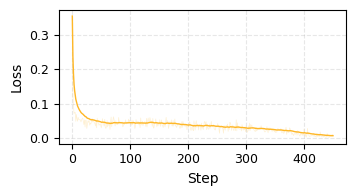

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mplt

sft_loss_file = 'sft_loss.csv'
grpo_rewards_file = 'grpo_rewards.csv'

raw_alpha = 0.2
raw_linewidth = 0.5
smooth_linewidth = 1.0
ema_alpha = 0.05  
font_label = 10
font_tick = 9
font_size = 8
font_family = 'Times New Roman'

mplt.rcParams['font.family'] = font_family
mplt.rcParams['font.size'] = font_size
# mplt.rcParams['text.usetex'] = True


data = pd.read_csv(sft_loss_file)
column_to_plot = [col for col in data.columns if "_MIN" not in col and "_MAX" not in col and col != "Step"]
print(f"Plotting columns: {column_to_plot}")

color = "#FEB727"
def ema_smooth(series, alpha=0.05):
    return series.ewm(alpha=alpha).mean()

fig, ax = plt.subplots(figsize=(3.6, 2))

for col in column_to_plot:
    ax.plot(data["Step"], data[col], label=col, alpha=raw_alpha, linewidth=raw_linewidth, color=color)
    ax.plot(data["Step"], ema_smooth(data[col], alpha=ema_alpha), label=f"{col} (EMA)", linewidth=smooth_linewidth, color=color)

ax.grid(True, linestyle='--', alpha=0.3)
ax.tick_params(axis='both', which='major', labelsize=font_tick)
ax.set_xlabel("Step", fontsize=font_label)
ax.set_ylabel("Loss", fontsize=font_label)
plt.tight_layout()
plt.show()